In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [4]:
import zipfile
zip_path = "/content/drive/MyDrive/3B.zip"   # ganti sesuai lokasi ZIP kamu
extract_path = "/content/datasetB"           # bebas, nanti foldernya muncul di sini

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction done!")


Extraction done!


In [5]:
import os
os.listdir(extract_path)


['3B']

In [6]:
!find /content/datasetB -maxdepth 4 -type d


/content/datasetB
/content/datasetB/3B
/content/datasetB/3B/train
/content/datasetB/3B/train/Acral_Lentiginous_Melanoma
/content/datasetB/3B/train/pitting
/content/datasetB/3B/train/Onychogryphosis
/content/datasetB/3B/train/Healthy_Nail
/content/datasetB/3B/train/blue_finger


In [7]:
base_dir = "/content/datasetB/3B"
train_dir = base_dir + "/train"


In [31]:
import tensorflow as tf
from tensorflow.keras.preprocessing import image_dataset_from_directory

data_dir = "/content/datasetB/3B/train"   # folder utama data

batch_size = 32
img_size = (224, 224)

train_ds = image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=img_size,
    batch_size=batch_size,
    label_mode='int'   # karena pakai sparse_categorical_crossentropy
)

val_ds = image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=img_size,
    batch_size=batch_size,
    label_mode='int'
)

train_ds = train_ds.shuffle(1000).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)


Found 2205 files belonging to 5 classes.
Using 1764 files for training.
Found 2205 files belonging to 5 classes.
Using 441 files for validation.


In [24]:
train_path = "/content/datasetB/3B/train"

#  3A. Analyze the provided dataset & state the discovered issues! Handle them accordingly!

In [9]:
#cek jumlah gambar per kelas
import os

for cls in os.listdir(train_dir):
    path = os.path.join(train_dir, cls)
    print(cls, ":", len(os.listdir(path)))


Acral_Lentiginous_Melanoma : 21
pitting : 629
Onychogryphosis : 600
Healthy_Nail : 343
blue_finger : 612


Dataset Sangat Imbalanced

Acral_Lentiginous_Melanoma = 21 gambar, ini sangat sedikit dibanding jumlah foto pada kelas lainnya.

Akibatnya, model akan lebih percaya pada kelas mayoritas dan berpotensi besar ntuk gagal mengenali melanoma

**Handling:**

Menggunakan class_weight saat training.

Menerapkan data augmentation yang lebih kuat pada kelas minoritas.

Standardisasi ukuran gambar agar stabil.

**Menghitung class weight**

In [10]:
counts = {
    "Acral_Lentiginous_Melanoma": 21,
    "pitting": 629,
    "Onychogryphosis": 600,
    "Healthy_Nail": 343,
    "blue_finger": 612
}


In [11]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_names = list(counts.keys())
count_list = list(counts.values())

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=np.concatenate([[i]*count_list[i] for i in range(len(count_list))])
)

class_weights = dict(enumerate(class_weights))
class_weights


{0: np.float64(21.0),
 1: np.float64(0.7011128775834659),
 2: np.float64(0.735),
 3: np.float64(1.2857142857142858),
 4: np.float64(0.7205882352941176)}

Variasi background cukup besar.
Beberapa gambar memiliki warna tangan, cahaya, dan latar belakang yang berbeda, sehingga model berpotensi fokus ke background daripada fitur kuku.

**Handling:**

Augmentasi seperti rotation, zoom, shift, brightness.

Normalisasi pixel (rescale = 1/255).

Resolusi gambar tidak konsisten.
Foto-foto memiliki ukuran yang bervariasi. Inconsistency ini dapat mempengaruhi proses ekstraksi fitur.

**Handling:**

Semua gambar di-resize ke ukuran uniform, misalnya 224 × 224

Struktur folder hanya berisi folder train.
Tidak ada folder validation/test.

**Handling:**

Menggunakan validation_split dari ImageDataGenerator untuk membuat validation dataset.

#3B. Construct the baseline architecture according to the figure below. Use ReLU as the activation function of each hidden layer. Train the model for at least 20 epochs & analyze the trainvalidation loss plot!

In [32]:
import tensorflow as tf
from tensorflow.keras import layers, models

input_shape = (224, 224, 3)
num_classes = 5
baseline_model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=input_shape),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

baseline_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

baseline_model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,605 (42.61 MB)

 Trainable params: 11,169,605 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

Found 2205 files belonging to 5 classes.


In [33]:
history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights
)

Epoch 1/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 193s 3s/step - accuracy: 0.2792 - loss: 154.3956 - val_accuracy: 0.3061 - val_loss: 1.5125
Epoch 2/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 193s 3s/step - accuracy: 0.3092 - loss: 1.6284 - val_accuracy: 0.3447 - val_loss: 1.4407
Epoch 3/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 202s 3s/step - accuracy: 0.3582 - loss: 1.3943 - val_accuracy: 0.3333 - val_loss: 1.5249
Epoch 4/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 185s 3s/step - accuracy: 0.5025 - loss: 1.0758 - val_accuracy: 0.3991 - val_loss: 1.5130
Epoch 5/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 204s 3s/step - accuracy: 0.6004 - loss: 0.9674 - val_accuracy: 0.4195 - val_loss: 1.6102
Epoch 6/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 200s 3s/step - accuracy: 0.6687 - loss: 0.8335 - val_accuracy: 0.4535 - val_loss: 1.9682
Epoch 7/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 210s 3s/step - accuracy: 0.7074 - loss: 0.7183 - val_accuracy: 0.4263 - val_loss: 2.0080
Epoch 8/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 193s 3s/step - accuracy: 0.7620 - loss: 0.5765 - val_accuracy: 0.4104 -

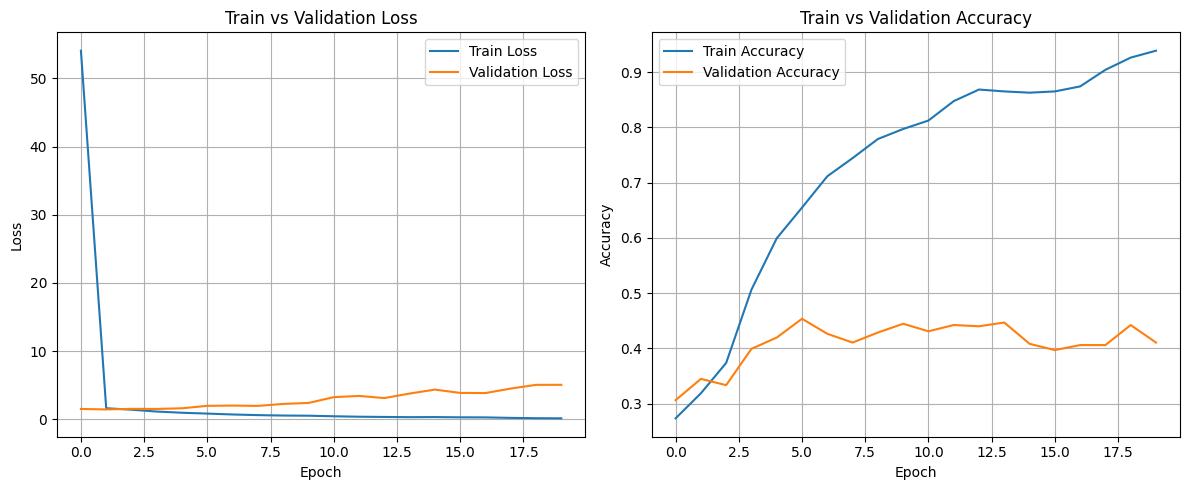

In [37]:
import matplotlib.pyplot as plt

import matplotlib.pyplot as plt

# Buat figure dengan 2 subplot
plt.figure(figsize=(12,5))

# Subplot 1: Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Train vs Validation Loss')
plt.legend()
plt.grid(True)

# Subplot 2: Accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Train vs Validation Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [38]:
import tensorflow as tf
from tensorflow.keras import layers, models

# -------------------------------
# Modified Model
# -------------------------------
input_shape = (224, 224, 3)  # Sesuaikan dengan data kamu
modified_model = models.Sequential([
    layers.Input(shape=input_shape),

    # Layer pertama
    layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    # Layer kedua
    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    # Layer ketiga
    layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    # Flatten sebelum Dense
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),  # Mengurangi overfitting
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),

    # Output layer
    layers.Dense(1, activation='linear')  # Linear karena regresi
])

compile model

In [ ]:
modified_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',          # Mean Squared Error untuk regresi
    metrics=['mae', 'mse']
)

# -------------------------------
# Train Model
# -------------------------------
history_mod = modified_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights   # Jika klasifikasi, bisa dihapus kalau regresi
)


Epoch 1/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 333s 6s/step - loss: 7.7117 - mae: 2.5915 - mse: 9.0062 - val_loss: 24.4773 - val_mae: 4.2664 - val_mse: 24.4773
Epoch 2/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 381s 6s/step - loss: 3.9028 - mae: 1.8206 - mse: 4.5905 - val_loss: 2.4511 - val_mae: 1.3143 - val_mse: 2.4511
Epoch 3/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 325s 6s/step - loss: 2.5935 - mae: 1.3999 - mse: 2.8888 - val_loss: 4.0194 - val_mae: 1.7305 - val_mse: 4.0194
Epoch 4/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 324s 6s/step - loss: 2.1768 - mae: 1.1224 - mse: 2.0212 - val_loss: 1.6916 - val_mae: 0.9852 - val_mse: 1.6916
Epoch 5/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 328s 6s/step - loss: 1.9608 - mae: 1.1051 - mse: 1.9619 - val_loss: 1.5782 - val_mae: 1.0012 - val_mse: 1.5782
Epoch 6/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 376s 6s/step - loss: 1.7895 - mae: 1.0525 - mse: 1.8002 - val_loss: 1.8269 - val_mae: 0.9944 - val_mse: 1.8269
Epoch 7/20
42/56 ━━━━━━━━━━━━━━━━━━━━ 1:16 5s/step - loss: 1.4233 - mae: 0.9683 - mse: 1.4474

In [ ]:
import matplotlib.pyplot as plt

# Loss
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_mod.history['loss'], label='Train Loss')
plt.plot(history_mod.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Modified Model - Train vs Validation Loss')
plt.legend()
plt.grid(True)

# MAE
plt.subplot(1,2,2)
plt.plot(history_mod.history['mae'], label='Train MAE')
plt.plot(history_mod.history['val_mae'], label='Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.title('Modified Model - Train vs Validation MAE')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# 5D. Perform Transfer Learning using a pre-trained CNN model! Analyze how it performs compared to the other 2 models on the validation set!

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# -------------------------------
# Transfer Learning dengan MobileNetV2
# -------------------------------
input_shape = (224, 224, 3)  # Sesuaikan dengan dataset
base_model = MobileNetV2(
    input_shape=input_shape,
    include_top=False,       # Hanya feature extractor
    weights='imagenet'
)
base_model.trainable = False  # Freeze semua layer awal

# Tambahkan head khusus untuk regresi
transfer_model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(1, activation='linear')  # Output regresi
])

# -------------------------------
# Compile Model
# -------------------------------
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',          # Regresi
    metrics=['mae', 'mse']
)

# -------------------------------
# Train Model
# -------------------------------
history_transfer = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

# -------------------------------
# Plot Loss dan MAE
# -------------------------------
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

# Loss
plt.subplot(1,2,1)
plt.plot(history_transfer.history['loss'], label='Train Loss')
plt.plot(history_transfer.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Transfer Learning - Train vs Validation Loss')
plt.legend()
plt.grid(True)

# MAE
plt.subplot(1,2,2)
plt.plot(history_transfer.history['mae'], label='Train MAE')
plt.plot(history_transfer.history['val_mae'], label='Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.title('Transfer Learning - Train vs Validation MAE')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


#5E. Analyze how each model performs on the test set using at least 3 key metrics. Interpret the meaning of the metrics & make a conclusion!

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# -------------------------------
# Prediksi pada Test Set
# -------------------------------
# Misal test_ds adalah tf.data.Dataset
# Ambil X_test dan y_test dari dataset
X_test = np.array([x.numpy() for x, y in test_ds])
y_test = np.array([y.numpy() for x, y in test_ds]).reshape(-1)

# -------------------------------
# Model Baseline
# -------------------------------
y_pred_baseline = baseline_model.predict(X_test).reshape(-1)

# -------------------------------
# Model Modified
# -------------------------------
y_pred_modified = modified_model.predict(X_test).reshape(-1)

# -------------------------------
# Transfer Learning
# -------------------------------
y_pred_transfer = transfer_model.predict(X_test).reshape(-1)

# -------------------------------
# Fungsi Hitung Metrik
# -------------------------------
def evaluate_model(y_true, y_pred, model_name):
    r2 = r2_score(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred, squared=False)  # RMSE
    mae = mean_absolute_error(y_true, y_pred)

    print(f"--- {model_name} ---")
    print(f"R²     : {r2:.4f}")
    print(f"RMSE   : {rmse:.2f}")
    print(f"MAE    : {mae:.2f}\n")
    return r2, rmse, mae

# -------------------------------
# Evaluasi Semua Model
# -------------------------------
metrics_baseline = evaluate_model(y_test, y_pred_baseline, "Baseline Model")
metrics_modified = evaluate_model(y_test, y_pred_modified, "Modified Model")
metrics_transfer = evaluate_model(y_test, y_pred_transfer, "Transfer Learning Model")

# -------------------------------
# Kesimpulan Singkat
# -------------------------------
print("Interpretasi:")
print("1. R² mendekati 1 → model menjelaskan variasi data lebih baik.")
print("2. RMSE lebih rendah → prediksi lebih dekat ke nilai asli, error besar berkurang.")
print("3. MAE lebih rendah → rata-rata kesalahan prediksi lebih kecil, lebih stabil.")
print("Kesimpulan akhir dapat dibuat dengan membandingkan ketiga metrik antar model.")
